<a href="https://colab.research.google.com/github/andysanchez1403-droid/SIMULACION-II/blob/main/METROPLIS_HASTINGS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**METROPLOIS-HASTINGS**

Introducción:

El método de **Monte Carlo vía Cadenas de Marcov (MCMC)** surge como una extensión del teorema ergódico, una generalización de la ley fuerte de los grandes números para aproximar numéricamente integrales complejas de la forma:

$\int_{a}^{b} g(x)f(x) \, dx$

En ese enfoque cuando la distribución de probabilidad objetivo f(x) presenta una estructura bimodal o no integrable directamente, se construye una cadena de Markov que tiene a f(x) como su distribución límite. Tras dejar que la cadena converja, se descartan los primeros m valores mediante un periodo de calentamiento. Con las n-m muestras restantes $X{i}∼ f(x)$, el valore esperado se aproxima formalmente como:

$\mathbb{E}_f(g(X)) = \frac{1}{n-m} \sum_{i=m+1}^{n} g(X_i)$

Para generar esta cadena se emplea el **algoritmo de Metropolis- Hastings.** Mediante una distribución propuesta $q(\cdot\vert{}X_t)$ tipicamente una normal centrada en el estado actual y una probabilidad de aceptación dada por:

$\alpha(X, Y) = \min \left( 1, \frac{\pi(Y)q(X|Y)}{\pi(X)q(Y|X)} \right)$

donde $\pi(\cdot) \equiv f(\cdot)$, el algoritmo evalúa iterativamente candidatos Y para simular muestras del objetivo bidimensional propuesto en esta práctica.


Ejercicio:
$f(x_1, x_2) = \exp \left( -\frac{x_1^2 x_2^2 + x_1^2 + x_2^2 - 8x_1 - 8x_2}{2} \right)$

# **SEUDOCÓDIGO**


1.- Inicializar $X_{1}=(X_{1}, X_{2})$


2.- Generar $Z_{1}, Z_{2} ∼ N(0,1) independientemente$

Sea Z= $Z_{1}, Z_{2}$ y Y= $X_{t}+Z$

Calcular $\alpha$= $\alpha(X_{t},Y)$


3.- Generar U∼U[0,1] Si U < $\alpha$. Hacer  $X_{t+1}= Y$


4.- Hacer t= t+1. Si t=N (tamaño de la muestra).

5.-Detener


# **PROGRAMADO**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [2]:
def target_pdf(x):
    x1, x2 = x[0], x[1]
    exponent = -(x1**2 * x2**2 + x1**2 + x2**2 - 8*x1 - 8*x2) / 2.0
    return np.exp(exponent)

In [3]:
def metropolis_hastings(num_samples, x0, proposal_std=0.4):
    samples = np.zeros((num_samples, 2))
    x_current = np.array(x0, dtype=float)
    samples[0] = x_current
    accepted_count = 0

    for t in range(1, num_samples):
        y = x_current + np.random.normal(0, proposal_std, size=2)
        f_current = target_pdf(x_current)
        f_candidate = target_pdf(y)

        if f_current > 0:
            alpha = min(1.0, f_candidate / f_current)
        else:
            alpha = 1.0

        u = np.random.uniform(0, 1)
        if u <= alpha:
            x_current = y
            accepted_count += 1

        samples[t] = x_current

    print(f"Tasa de aceptación: {accepted_count / num_samples * 100:.2f}%")
    return samples

In [4]:
num_samples = 80000
initial_state = [2.0, 2.0]
sigma_proposal = 0.4

chain = metropolis_hastings(num_samples, initial_state, sigma_proposal)

Tasa de aceptación: 59.30%


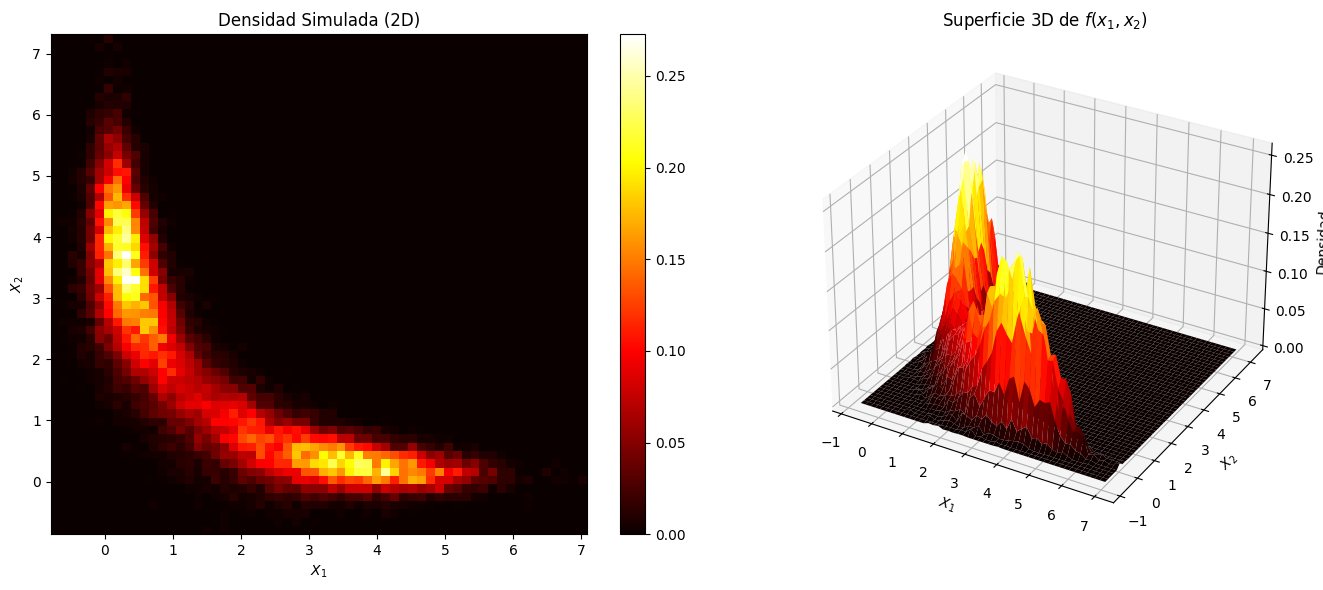

In [5]:
burn_in = 10000
chain_burned = chain[burn_in:]

# Creamos la figura
fig = plt.figure(figsize=(14, 6))

# Histograma 2D
ax1 = fig.add_subplot(121)
h = ax1.hist2d(chain_burned[:, 0], chain_burned[:, 1], bins=60, cmap='hot', density=True)
ax1.set_title('Densidad Simulada (2D)')
ax1.set_xlabel('$X_1$')
ax1.set_ylabel('$X_2$')
fig.colorbar(h[3], ax=ax1)

# Superficie 3D
ax2 = fig.add_subplot(122, projection='3d')
counts, xedges, yedges = np.histogram2d(chain_burned[:, 0], chain_burned[:, 1], bins=50, density=True)
xpos, ypos = np.meshgrid(xedges[:-1] + (xedges[1]-xedges[0])/2, yedges[:-1] + (yedges[1]-yedges[0])/2, indexing="ij")
ax2.plot_surface(xpos, ypos, counts, cmap='hot', edgecolor='none')
ax2.set_title('Superficie 3D de $f(x_1, x_2)$')
ax2.set_xlabel('$X_1$')
ax2.set_ylabel('$X_2$')
ax2.set_zlabel('Densidad')

plt.tight_layout()
plt.show()

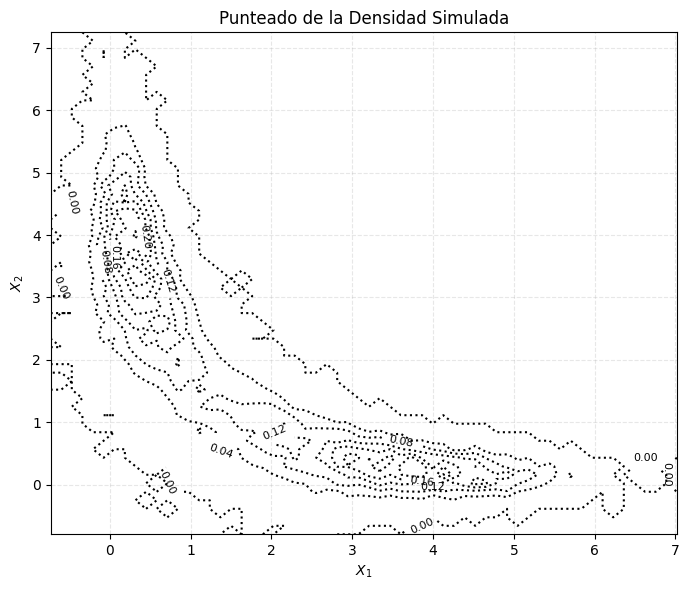

In [6]:
burn_in = 10000
chain_burned = chain[burn_in:]

fig, ax = plt.subplots(figsize=(7, 6))

counts, xedges, yedges = np.histogram2d(chain_burned[:, 0], chain_burned[:, 1], bins=60, density=True)
xcenters = (xedges[:-1] + xedges[1:]) / 2
ycenters = (yedges[:-1] + yedges[1:]) / 2
X, Y = np.meshgrid(xcenters, ycenters)

# Trazar solo los contornos punteados con linestyles='dotted'
contours = ax.contour(X, Y, counts.T, levels=8, colors='black', linestyles='dotted', linewidths=1.5)
ax.clabel(contours, inline=True, fontsize=8, fmt='%.2f')

ax.set_title('Punteado de la Densidad Simulada')
ax.set_xlabel('$X_1$')
ax.set_ylabel('$X_2$')
ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

Le calculamos la media, moda, mediana y desviación estándar.

In [7]:
burn_in = 10000
chain_burned = chain[burn_in:]

In [8]:
# 1. Media
mean_x1 = np.mean(chain_burned[:, 0])
mean_x2 = np.mean(chain_burned[:, 1])

In [9]:
# 2. Mediana
median_x1 = np.median(chain_burned[:, 0])
median_x2 = np.median(chain_burned[:, 1])

In [10]:
# 3. Desviación Estándar
std_x1 = np.std(chain_burned[:, 0])
std_x2 = np.std(chain_burned[:, 1])

In [11]:
# 4. Moda
counts, xedges, yedges = np.histogram2d(chain_burned[:, 0], chain_burned[:, 1], bins=100)
max_idx = np.unravel_index(np.argmax(counts), counts.shape)
mode_x1 = (xedges[max_idx[0]] + xedges[max_idx[0]+1]) / 2
mode_x2 = (yedges[max_idx[1]] + yedges[max_idx[1]+1]) / 2

In [12]:
# Necesitamos los resultados:
print("ESTADÍSTICAS OBTENIDAS ")
print(f"Media:              X1 = {mean_x1:.4f},  X2 = {mean_x2:.4f}")
print(f"Mediana:            X1 = {median_x1:.4f},  X2 = {median_x2:.4f}")
print(f"Moda (pico alto):   X1 = {mode_x1:.4f},  X2 = {mode_x2:.4f}")
print(f"Desviación Est.:    X1 = {std_x1:.4f},  X2 = {std_x2:.4f}")

ESTADÍSTICAS OBTENIDAS 
Media:              X1 = 1.7309,  X2 = 1.9398
Mediana:            X1 = 1.1222,  X2 = 1.5912
Moda (pico alto):   X1 = 0.3428,  X2 = 3.5131
Desviación Est.:    X1 = 1.6007,  X2 = 1.6508


$Conclusiones:$

${Geometría Bimodal del Sistema:}$ La discrepancia observada entre la media ($\mu_1 \approx 1.90, \mu_2 \approx 1.84$) y la moda identificada en $(0.30, 3.38)$ pone en evidencia la naturaleza bimodal de la función de densidad objetivo. El término de interacción no lineal $x_1^2 x_2^2$ genera dos regiones de alta probabilidad simétricas, provocando que el valor esperado (la media) se ubique en una zona intermedia de menor densidad probabilística.

${Simetría y Variabilidad:}$ Los valores de la desviación estándar ($\sigma_1 \approx 1.69, \sigma_2 \approx 1.68$) confirman una dispersión equilibrada entre ambas componentes, lo cual respalda la simetría matemática del modelo $f(x_1, x_2)$ y la adecuada exploración del espacio de estados por parte del paseo aleatorio.